# 03 — Model Evaluation
**GameGuard AI · Toxicity classification**

**Goal:** Check how reliable our trained **TF-IDF + Logistic Regression baseline** is, beyond accuracy alone.

**Inputs**
- `models/tfidf_logistic_regression.joblib` — trained in `02_Model_Development.ipynb`
- `data/processed/validation.csv` — previously unseen during model fitting

**What we investigate:** classification errors, probability quality, decision thresholds, gaming language, and multilingual examples.

> **Important:** This notebook evaluates the existing baseline; it does not retrain it. We deliberately **do not open `test.csv`**. That dataset stays untouched until the final model comparison and evaluation. The examples in later sections are *qualitative checks*, not additional accuracy benchmarks.

## 1. Load the trained model and validation data
We reload the **entire saved pipeline**, including its TF-IDF vectorizer, so text is processed exactly as it was during training.

Here, `0 = Not Toxic` and `1 = Toxic`. The model's `predict_proba` output provides an **estimated** toxicity probability; we still need to check whether those estimates are trustworthy.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.calibration import calibration_curve

# Find the project root from either GameGuard-AI/ or GameGuard-AI/notebooks/.
ROOT = next(
    (
        folder for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "models" / "tfidf_logistic_regression.joblib").is_file()
        and (folder / "data" / "processed" / "validation.csv").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Missing model or validation data. Run 02_Model_Development.ipynb first."
    )

model = joblib.load(ROOT / "models" / "tfidf_logistic_regression.joblib")
validation = pd.read_csv(ROOT / "data" / "processed" / "validation.csv")

if not {"message", "label"}.issubset(validation.columns):
    raise ValueError("validation.csv must have 'message' and 'label' columns.")
if validation[["message", "label"]].isna().any().any():
    raise ValueError("Validation data contains missing messages or labels.")
if not set(validation["label"].unique()).issubset({0, 1}):
    raise ValueError("Validation labels must be binary: 0 or 1.")
if len(validation) == 0:
    raise ValueError("Validation data is empty.")
if not hasattr(model, "predict_proba") or 1 not in model.classes_:
    raise ValueError("The saved model must support probabilities for Toxic (class 1).")

X_val = validation["message"].astype(str)
y_val = validation["label"].astype(int)

# Use the class labels rather than assuming Toxic is always column 2.
toxic_index = list(model.classes_).index(1)
toxic_probability = model.predict_proba(X_val)[:, toxic_index]
predicted = (toxic_probability >= 0.50).astype(int)

print(f"Validation messages: {len(validation):,}")
print(f"Actual toxic messages: {y_val.sum():,} ({y_val.mean():.1%})")
print("Baseline model loaded successfully.")

Validation messages: 4,113
Actual toxic messages: 998 (24.3%)
Baseline model loaded successfully.


## 2. Check classification performance
The default decision threshold is **50%**: messages with an estimated toxicity probability of at least 0.50 are flagged Toxic.

We care about more than accuracy:
- **Toxic precision:** How many flagged messages really are toxic?
- **Toxic recall:** How many of the toxic messages were caught?
- **Toxic F1:** A balance between precision and recall.

The confusion matrix also shows **false positives** (harmless messages flagged) and **false negatives** (toxic messages missed).

,Accuracy,Toxic precision,Toxic recall,Toxic F1,Macro F1
0,88.89%,75.45%,80.36%,77.83%,85.21%


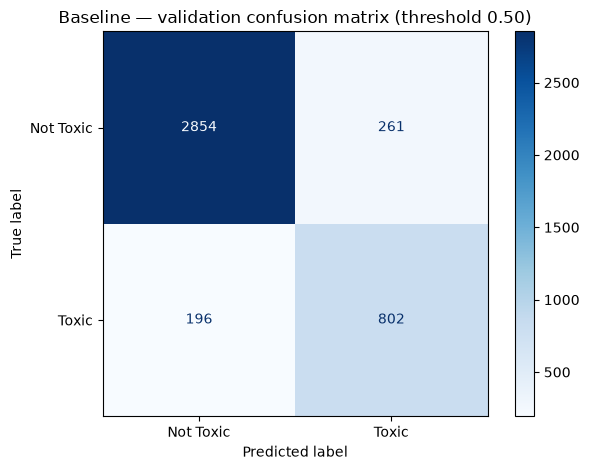

In [2]:
metrics = pd.DataFrame([{
    "Accuracy": accuracy_score(y_val, predicted),
    "Toxic precision": precision_score(y_val, predicted, zero_division=0),
    "Toxic recall": recall_score(y_val, predicted, zero_division=0),
    "Toxic F1": f1_score(y_val, predicted, zero_division=0),
    "Macro F1": f1_score(y_val, predicted, average="macro", zero_division=0),
}])

display(metrics.style.format("{:.2%}"))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    predicted,
    labels=[0, 1],
    display_labels=["Not Toxic", "Toxic"],
    cmap="Blues",
    values_format="d",
)
plt.title("Baseline — validation confusion matrix (threshold 0.50)")
plt.tight_layout()
plt.show()

## 3. Are the probabilities reliable?
A model can predict the right label but still give **misleading probabilities**. For example, among messages assigned roughly 80% toxicity probability, ideally about 80% would actually be toxic. This property is called **calibration**.

We measure:
- **Brier score:** Average squared error between probabilities and actual labels (**lower is better**).
- **ROC AUC:** How well the model ranks toxic messages ahead of non-toxic messages.
- **Average precision (PR):** A useful ranking metric when the toxic class is less common.

We also compare the Brier score with a simple baseline that predicts the **same toxic rate for every message**. The calibration plot compares predicted probabilities against the observed toxic fraction. These checks are descriptive; there is no universal cutoff proving a model is safe.

,Model Brier score,Constant-rate Brier score,ROC AUC,Average precision,Toxic prevalence
0,0.1015,0.1838,0.9262,0.8307,0.2426


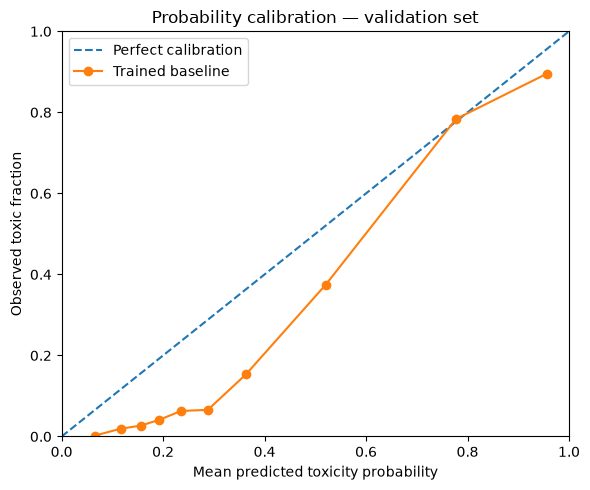

Brier score beats the constant-rate baseline (lower is better).
Remember: class_weight='balanced' does not guarantee calibrated probabilities.


In [3]:
toxic_rate = y_val.mean()
probability_metrics = pd.DataFrame([{
    "Model Brier score": brier_score_loss(y_val, toxic_probability),
    "Constant-rate Brier score": brier_score_loss(
        y_val, np.full(len(y_val), toxic_rate)
    ),
    "ROC AUC": roc_auc_score(y_val, toxic_probability),
    "Average precision": average_precision_score(y_val, toxic_probability),
    "Toxic prevalence": toxic_rate,
}])
display(probability_metrics.round(4))

# Equal-frequency bins make each calibration point easier to compare.
observed_rate, predicted_rate = calibration_curve(
    y_val, toxic_probability, n_bins=10, strategy="quantile"
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", label="Perfect calibration")
ax.plot(predicted_rate, observed_rate, marker="o", label="Trained baseline")
ax.set(
    xlabel="Mean predicted toxicity probability",
    ylabel="Observed toxic fraction",
    title="Probability calibration — validation set",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend()
plt.tight_layout()
plt.show()

if probability_metrics.loc[0, "Model Brier score"] < probability_metrics.loc[0, "Constant-rate Brier score"]:
    print("Brier score beats the constant-rate baseline (lower is better).")
else:
    print("Brier score does not beat the constant-rate baseline; investigate calibration.")
print("Remember: class_weight='balanced' does not guarantee calibrated probabilities.")

## 4. Explore the decision threshold
The default **0.50 threshold** is not automatically the best choice for GameGuard AI. Lowering the threshold may catch more toxicity but can also flag more harmless messages.

We compare several thresholds **using validation data only**. This helps us understand the trade-off, but a threshold chosen here will still need independent evaluation later. We do **not** modify the saved model or claim a new final score.

In [4]:
threshold_rows = []
for threshold in np.round(np.arange(0.10, 0.91, 0.05), 2):
    threshold_predictions = (toxic_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Toxic precision": precision_score(y_val, threshold_predictions, zero_division=0),
        "Toxic recall": recall_score(y_val, threshold_predictions, zero_division=0),
        "Toxic F1": f1_score(y_val, threshold_predictions, zero_division=0),
        "False positives": int(((y_val == 0) & (threshold_predictions == 1)).sum()),
        "False negatives": int(((y_val == 1) & (threshold_predictions == 0)).sum()),
    })

threshold_results = pd.DataFrame(threshold_rows)
best_validation_row = threshold_results.loc[threshold_results["Toxic F1"].idxmax()]

# Show the default, highest-F1-on-validation, and neighboring thresholds.
interesting = set([0.50, float(best_validation_row["Threshold"])])
interesting.update([
    round(max(0.10, best_validation_row["Threshold"] - 0.05), 2),
    round(min(0.90, best_validation_row["Threshold"] + 0.05), 2),
])
preview = threshold_results[threshold_results["Threshold"].isin(interesting)].copy()
display(preview.style.format({
    "Threshold": "{:.2f}",
    "Toxic precision": "{:.2%}",
    "Toxic recall": "{:.2%}",
    "Toxic F1": "{:.2%}",
}))

print(f"Best validation F1 among checked thresholds: {best_validation_row['Threshold']:.2f}")
print("This is a validation-selected setting, NOT an independently tested result.")

,Threshold,Toxic precision,Toxic recall,Toxic F1,False positives,False negatives
7,0.45,71.68%,82.67%,76.78%,326,173
8,0.50,75.45%,80.36%,77.83%,261,196
9,0.55,78.53%,76.25%,77.38%,208,237


Best validation F1 among checked thresholds: 0.50
This is a validation-selected setting, NOT an independently tested result.


## 5. Test realistic gaming expressions
A high validation score does not guarantee that the model understands insults, sarcasm, or slang from every game.

The examples below are **manual probes**. We inspect their predicted labels and scores; **we do not compute accuracy from them**. Some messages need conversation history to interpret fairly.

In [5]:
gaming_examples = pd.DataFrame([
    ("Friendly", "gg wp, that was a close match"),
    ("Friendly", "nice try, we'll get them next round"),
    ("Insult", "you're trash, uninstall the game"),
    ("Insult", "our jungler is useless"),
    ("Insult", "ur so bad at this game"),
    ("Game frustration", "I hate this map"),
    ("Connection issue", "trash wifi"),
    ("Direct insult", "you're trash"),
    ("Sarcasm / ambiguous", "nice job, genius"),
    ("Sarcasm / ambiguous", "wow, amazing aim..."),
    ("Gaming slang", "gg ez"),
    ("Gaming slang", "diff"),
], columns=["Example type", "Message"])

gaming_probability = model.predict_proba(gaming_examples["Message"])[:, toxic_index]
gaming_examples["Prediction"] = np.where(gaming_probability >= 0.50, "Toxic", "Not Toxic")
gaming_examples["Toxicity probability"] = (100 * gaming_probability).round(1)

display(gaming_examples)
print("Illustrative inputs only. Sarcasm and slang may require context or human review.")

,Example type,Message,Prediction,Toxicity probability
0,Friendly,"gg wp, that was a close match",Not Toxic,27.3
1,Friendly,"nice try, we'll get them next round",Not Toxic,7.3
2,Insult,"you're trash, uninstall the game",Toxic,94.5
3,Insult,our jungler is useless,Toxic,94.6
4,Insult,ur so bad at this game,Toxic,84.0
5,Game frustration,I hate this map,Toxic,68.1
6,Connection issue,trash wifi,Toxic,82.1
7,Direct insult,you're trash,Toxic,74.2
8,Sarcasm / ambiguous,"nice job, genius",Not Toxic,30.6
9,Sarcasm / ambiguous,"wow, amazing aim...",Not Toxic,35.9


Illustrative inputs only. Sarcasm and slang may require context or human review.


## 6. Explore other languages
The current TF-IDF model does **not** automatically detect or translate languages. It looks for character patterns learned from its training data. A message in Dutch, Spanish, French, Russian, or Chinese may therefore behave differently.

This **small multilingual probe** checks whether predictions look plausible. The examples are not a representative multilingual benchmark, and a few correct results do **not** establish multilingual support. We need language-identified, human-labeled test data to compare accuracy by language.

In [6]:
language_examples = pd.DataFrame([
    ("Dutch", "goed gespeeld"),
    ("Dutch", "je bent waardeloos"),
    ("Spanish", "bien jugado"),
    ("Spanish", "eres un inútil"),
    ("French", "bien joué"),
    ("French", "tu es nul"),
    ("Russian", "хорошая игра"),
    ("Russian", "ты бесполезен"),
    ("Chinese", "打得好"),
    ("Chinese", "你真係廢"),
], columns=["Language", "Message"])

language_probability = model.predict_proba(language_examples["Message"])[:, toxic_index]
language_examples["Prediction"] = np.where(
    language_probability >= 0.50, "Toxic", "Not Toxic"
)
language_examples["Toxicity probability"] = (100 * language_probability).round(1)

display(language_examples)
print("Exploratory only: do not report these ten examples as multilingual accuracy.")

,Language,Message,Prediction,Toxicity probability
0,Dutch,goed gespeeld,Not Toxic,15.7
1,Dutch,je bent waardeloos,Not Toxic,40.4
2,Spanish,bien jugado,Not Toxic,23.1
3,Spanish,eres un inútil,Not Toxic,22.0
4,French,bien joué,Not Toxic,25.2
5,French,tu es nul,Not Toxic,27.1
6,Russian,хорошая игра,Not Toxic,31.4
7,Russian,ты бесполезен,Toxic,65.9
8,Chinese,打得好,Not Toxic,23.2
9,Chinese,你真係廢,Not Toxic,23.2


Exploratory only: do not report these ten examples as multilingual accuracy.


## 7. Improving Probability Calibration

The previous evaluation showed that our model's predicted toxicity
probabilities do not always match the observed toxicity rates.

To improve probability reliability, we test sigmoid calibration
using three-fold cross-validation on the training dataset.

We compare the original and calibrated models using:
- Brier score (lower is better)
- Accuracy
- Toxic-class F1-score
- Calibration curves

The validation dataset is used only for comparison, not calibration
training. The final test dataset remains untouched.

In [7]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold

# Load the original training data.
train = pd.read_csv(ROOT / "data" / "processed" / "train.csv")

X_train = train["message"].astype(str)
y_train = train["label"].astype(int)

# Create a calibrated copy of the original model.
# Cross-validation avoids calibrating on a model's own fitted predictions.
calibrated_model = CalibratedClassifierCV(
    estimator=clone(model),
    method="sigmoid",
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    ),
    ensemble=False
)

calibrated_model.fit(X_train, y_train)

# Evaluate using the same validation messages.
calibrated_probability = calibrated_model.predict_proba(X_val)[
    :, list(calibrated_model.classes_).index(1)
]

print("Calibration completed.")

Calibration completed.


,Model,Brier score,Accuracy,Toxic F1
0,Original,0.1015,0.8889,0.7783
1,Calibrated,0.0824,0.8928,0.7591


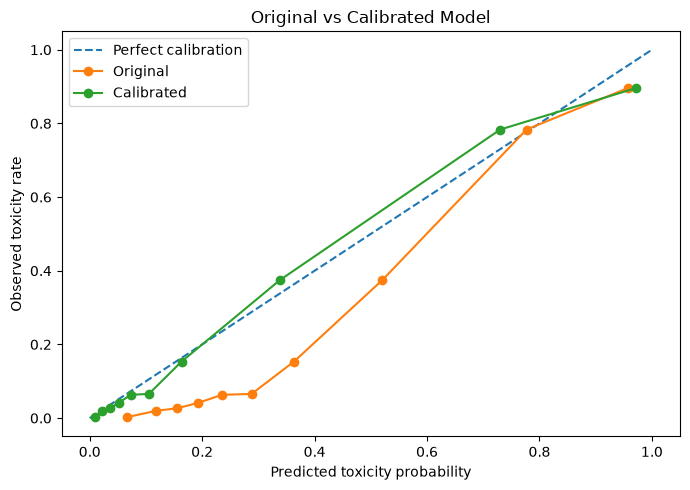

In [8]:
comparison = pd.DataFrame([
    {
        "Model": "Original",
        "Brier score": brier_score_loss(y_val, toxic_probability),
        "Accuracy": accuracy_score(y_val, toxic_probability >= 0.5),
        "Toxic F1": f1_score(y_val, toxic_probability >= 0.5),
    },
    {
        "Model": "Calibrated",
        "Brier score": brier_score_loss(y_val, calibrated_probability),
        "Accuracy": accuracy_score(y_val, calibrated_probability >= 0.5),
        "Toxic F1": f1_score(y_val, calibrated_probability >= 0.5),
    }
])

display(comparison.round(4))

# Compare probability calibration.
plt.figure(figsize=(7, 5))

plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")

for name, probabilities in [
    ("Original", toxic_probability),
    ("Calibrated", calibrated_probability)
]:
    observed, predicted_mean = calibration_curve(
        y_val,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(predicted_mean, observed, marker="o", label=name)

plt.xlabel("Predicted toxicity probability")
plt.ylabel("Observed toxicity rate")
plt.title("Original vs Calibrated Model")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
calibrated_path = ROOT / "models" / "tfidf_logistic_regression_calibrated.joblib"

joblib.dump(calibrated_model, calibrated_path)

print(f"Saved calibrated candidate: {calibrated_path.name}")

Saved calibrated candidate: tfidf_logistic_regression_calibrated.joblib


In [10]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.05):
    predictions = (calibrated_probability >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "Toxic F1": f1_score(y_val, predictions, zero_division=0),
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

best = threshold_df.loc[threshold_df["Toxic F1"].idxmax()]

print(f"Best validation threshold: {best['Threshold']:.2f}")
print(f"Toxic F1: {best['Toxic F1']:.2%}")
print(f"Toxic recall: {best['Recall']:.2%}")

,Threshold,Precision,Recall,Toxic F1
0,0.20,0.6748,0.8567,0.7550
1,0.25,0.7184,0.8257,0.7683
2,0.30,0.7519,0.8046,0.7773
3,0.35,0.7748,0.7756,0.7752
4,0.40,0.7968,0.7465,0.7708
5,0.45,0.8203,0.7275,0.7711
6,0.50,0.8343,0.6964,0.7591
7,0.55,0.8492,0.6713,0.7499
8,0.60,0.8589,0.6343,0.7297
9,0.65,0.8709,0.6082,0.7162


Best validation threshold: 0.30
Toxic F1: 77.73%
Toxic recall: 80.46%


In [11]:
from pathlib import Path
import joblib

model_bundle = {
    "model": calibrated_model,
    "threshold": 0.30,
    "model_name": "TF-IDF + Calibrated Logistic Regression"
}

output_path = ROOT / "models" / "gameguard_baseline.joblib"

joblib.dump(model_bundle, output_path)

print(f"Saved baseline: {output_path}")
print("Decision threshold: 0.30")

Saved baseline: c:\Users\aweso\Downloads\GameGuard-AI-Project\GameGuard-AI\models\gameguard_baseline.joblib
Decision threshold: 0.30


## Final Baseline Evaluation

The calibrated Logistic Regression model is evaluated on the
previously untouched test dataset.

The model and decision threshold were selected using validation data.

Selected configuration:
- Model: Character TF-IDF + Calibrated Logistic Regression
- Calibration: Sigmoid
- Decision threshold: 0.30

This evaluation measures how well the baseline generalizes to
unseen gaming messages.

No retraining, threshold optimization, or model selection is
performed using the test dataset.

Test messages: 4,114
Decision threshold: 0.30


,Accuracy,Toxic precision,Toxic recall,Toxic F1,Macro F1,Brier score,ROC AUC,Average precision
0,0.8938,0.7799,0.7838,0.7818,0.8558,0.081,0.9268,0.8378


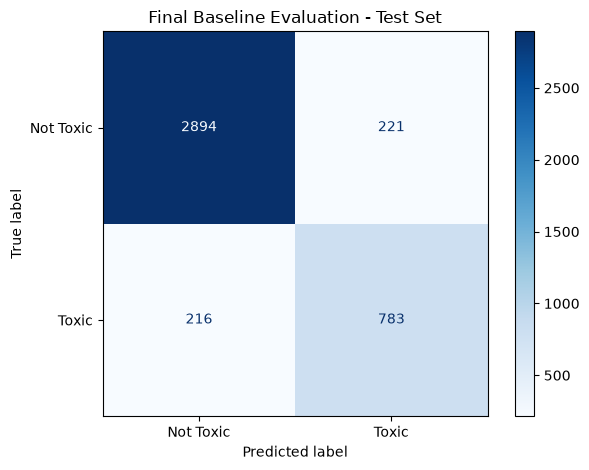

Correct toxic detections: 783
Missed toxic messages: 216
False toxic alarms: 221
Correct non-toxic detections: 2894


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

# Load the finalized baseline and untouched test dataset.
bundle = joblib.load(ROOT / "models" / "gameguard_baseline.joblib")

final_model = bundle["model"]
final_threshold = bundle["threshold"]

test = pd.read_csv(ROOT / "data" / "processed" / "test.csv")

assert {"message", "label"}.issubset(test.columns)
assert not test[["message", "label"]].isna().any().any()
assert set(test["label"].unique()) == {0, 1}
assert 0 <= final_threshold <= 1

X_test = test["message"].astype(str)
y_test = test["label"].astype(int)

# Obtain toxicity probabilities from the calibrated model.
toxic_index = list(final_model.classes_).index(1)
test_probability = final_model.predict_proba(X_test)[:, toxic_index]

# Use the previously selected threshold. Do not tune on test data.
test_predictions = (test_probability >= final_threshold).astype(int)

# Evaluate classification and probability quality.
final_results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Toxic precision": precision_score(y_test, test_predictions),
    "Toxic recall": recall_score(y_test, test_predictions),
    "Toxic F1": f1_score(y_test, test_predictions),
    "Macro F1": f1_score(y_test, test_predictions, average="macro"),
    "Brier score": brier_score_loss(y_test, test_probability),
    "ROC AUC": roc_auc_score(y_test, test_probability),
    "Average precision": average_precision_score(y_test, test_probability),
}])

print(f"Test messages: {len(test):,}")
print(f"Decision threshold: {final_threshold:.2f}")

display(final_results.round(4))

# Display the confusion matrix.
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Toxic", "Toxic"]
).plot(cmap="Blues", values_format="d")

plt.title("Final Baseline Evaluation - Test Set")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print(f"Correct toxic detections: {tp}")
print(f"Missed toxic messages: {fn}")
print(f"False toxic alarms: {fp}")
print(f"Correct non-toxic detections: {tn}")